# Replace Group with Pseudotime

This notebook calculates pseudotime and replaces the Group column with pseudotime values.

In [1]:
import numpy as np
import scanpy as sc
import warnings

warnings.simplefilter(action="ignore", category=Warning)
sc.settings.verbosity = 3

In [2]:
import scanpy as sc

adata_train = sc.read_h5ad("diff_train.h5ad")
print("train data", adata_train)
adata_test = sc.read_h5ad("diff_test.h5ad")
print("test data", adata_test)

# add label
adata_train.obs["dataset"] = "train"
adata_test.obs["dataset"] = "test"

adata_origin = sc.concat(
    {"train": adata_train, "test": adata_test},
    label="dataset",
    join="outer"
)

print(adata_origin.obs["dataset"].value_counts())

train data AnnData object with n_obs × n_vars = 2400 × 203
    obs: 'Group'
test data AnnData object with n_obs × n_vars = 2400 × 203
    obs: 'Group'
dataset
train    2400
test     2400
Name: count, dtype: int64


## Load Original Data

In [3]:

print(f"Original data shape: {adata_origin.shape}")
print(f"Original Group values: {adata_origin.obs['Group'].unique()}")
print(f"Available representations: {list(adata_origin.obsm.keys())}")
print(adata_origin.obs['Group'].unique())
print(adata_origin.obs)

Original data shape: (4800, 203)
Original Group values: [3, 0, 1, 2]
Categories (4, int64): [0, 1, 2, 3]
Available representations: []
[3, 0, 1, 2]
Categories (4, int64): [0, 1, 2, 3]
                 Group dataset
25475_4#319-day3     3   train
24229_5#259-day3     3   train
25013_5#163-day3     3   train
24539_1#53-day3      3   train
25271_4#104-day3     3   train
...                ...     ...
24252_1#352-day2     2    test
25013_8#316-day2     2    test
23794_4#39-day2      2    test
21554_5#308-day2     2    test
24539_5#164-day2     2    test

[4800 rows x 2 columns]


## Compute Neighbors and UMAP

computing PCA
    with n_comps=50
    finished (0:00:00)
computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:05)
computing Diffusion Maps using n_comps=15(=n_dcs)
computing transitions
    finished (0:00:00)
    eigenvalues of transition matrix
    [1.         0.99155134 0.96942633 0.9617836  0.96072525 0.9498147
     0.93868506 0.9327397  0.9015645  0.89087427 0.8876453  0.87915605
     0.871046   0.8669183  0.8664098 ]
    finished: added
    'X_diffmap', diffmap coordinates (adata.obsm)
    'diffmap_evals', eigenvalues of transition matrix (adata.uns) (0:00:00)
computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
running PAGA
    finished: adde

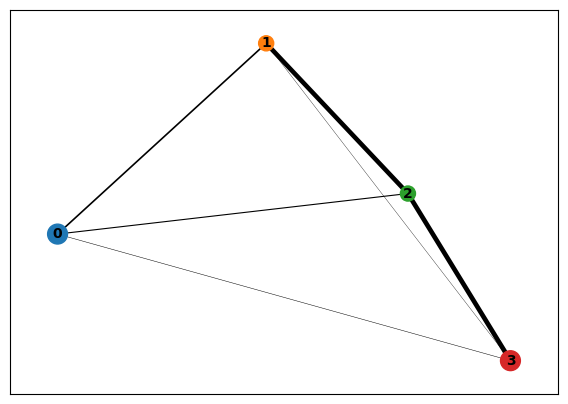

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:09)


In [4]:
adata = adata_origin.copy()
sc.tl.pca(adata, svd_solver="arpack")
sc.pp.neighbors(adata)

sc.tl.diffmap(adata)
sc.pp.neighbors(adata)
sc.tl.paga(adata, groups="Group")

sc.pl.paga(
    adata,
    color=["Group"]
)
sc.tl.umap(adata)

## Set Root Cell for Pseudotime

Choose a root cell from the starting population (typically early progenitors or stem cells).

In [5]:
# Display available groups to help choose root
print("Available Groups:")
print(adata.obs['Group'].value_counts())

# # Automatically select root from first group (or modify this)
# root_group = adata.obs['Group'].unique()[0]
# print(f"\nUsing '{root_group}' as root group")
# print("** MODIFY root_group VARIABLE IF YOU WANT A DIFFERENT STARTING POINT **")

# Set root cell
root_group = 0
print(f"\nUsing Group == {root_group} as root group")

# Set root cell - pick first cell where Group == 0
root_ixs = np.flatnonzero(adata.obs['Group'] == root_group)
if len(root_ixs) == 0:
    raise ValueError(f"No cells found with Group == {root_group}")
adata.uns['iroot'] = root_ixs[0]
print(f"Root cell index: {adata.uns['iroot']}")


Available Groups:
Group
0    1800
3    1800
1     600
2     600
Name: count, dtype: int64

Using Group == 0 as root group
Root cell index: 1200


In [6]:
# Print obs information for index 1200
print(f"\nObs information for index 1200:")
print(adata.obs.iloc[1200])


Obs information for index 1200:
Group          0
dataset    train
Name: 21672_1#53-day0, dtype: object


## Calculate Pseudotime

In [7]:
# Calculate diffusion pseudotime
# print("Computing diffusion map...")
# sc.tl.diffmap(adata, n_comps=15)

print("Computing pseudotime...")
sc.tl.dpt(adata)

print(f"\nPseudotime calculated!")
print(f"Pseudotime range: {adata.obs['dpt_pseudotime'].min():.4f} to {adata.obs['dpt_pseudotime'].max():.4f}")

Computing pseudotime...
computing Diffusion Pseudotime using n_dcs=10
    finished: added
    'dpt_pseudotime', the pseudotime (adata.obs) (0:00:00)

Pseudotime calculated!
Pseudotime range: 0.0000 to 1.0000


## Replace Group with Pseudotime

In [8]:
# Store original Group as backup
adata.obs['Group_original'] = adata.obs['Group'].copy()

# # Scale pseudotime based on original group
# # Group 0: pseudotime 0-0.99
# # Group 3: pseudotime 3-3.99
# pseudotime_scaled = np.zeros(len(adata.obs))

# for group_val in adata.obs['Group_original'].unique():
#     mask = adata.obs['Group_original'] == group_val
#     group_pseudotime = adata.obs.loc[mask, 'dpt_pseudotime']
    
#     # Normalize to 0-0.99 range within this group
#     pt_min = group_pseudotime.min()
#     pt_max = group_pseudotime.max()
    
#     if pt_max > pt_min:esxxx
#         normalized = (group_pseudotime - pt_min) / (pt_max - pt_min) * 0.99
#     else:
#         normalized = group_pseudotime * 0
    
#     # Shift to appropriate range: group_val to group_val+0.99
#     pseudotime_scaled[mask] = group_val + normalized

# Replace Group with scaled pseudotime
adata.obs['Group'] = adata.obs['dpt_pseudotime']

print("✓ Replaced obs['Group'] with scaled pseudotime values")
print(f"\nNew Group values (scaled pseudotime):")
for group_val in sorted(adata.obs['Group_original'].unique()):
    mask = adata.obs['Group_original'] == group_val
    group_data = adata.obs.loc[mask, 'Group']
    print(f"  Original Group {group_val}: {group_data.min():.4f} to {group_data.max():.4f}")
print(f"\nOriginal Group labels saved in obs['Group_original']")


✓ Replaced obs['Group'] with scaled pseudotime values

New Group values (scaled pseudotime):
  Original Group 0: 0.0000 to 1.0000
  Original Group 1: 0.0526 to 0.9255
  Original Group 2: 0.0364 to 0.6730
  Original Group 3: 0.0261 to 0.9368

Original Group labels saved in obs['Group_original']


## Visualize (Optional)

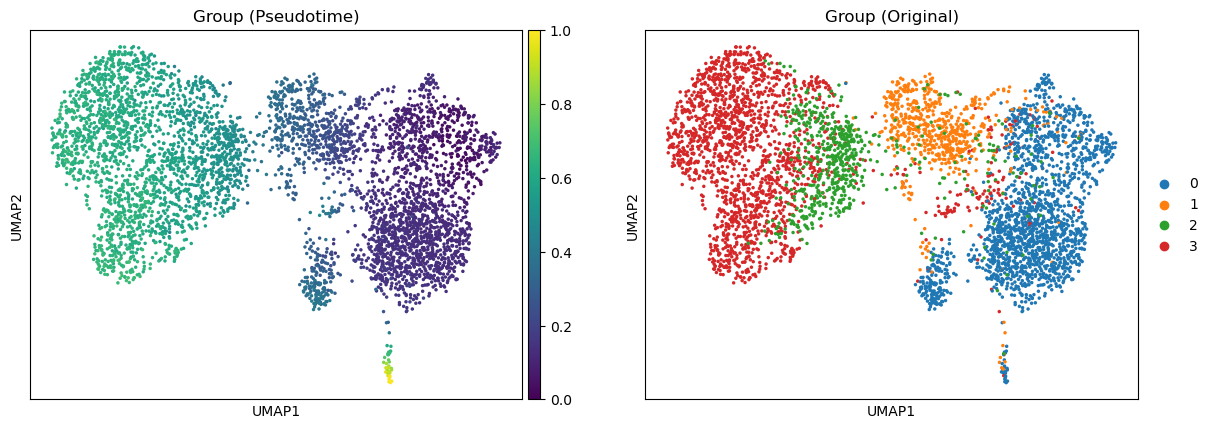

In [9]:
# Visualize the pseudotime on UMAP
sc.pl.umap(adata, color=['Group', 'Group_original'], 
           ncols=2, cmap='viridis',
           title=['Group (Pseudotime)', 'Group (Original)'])

## Save as New File

In [10]:
# Save as train.h5ad
output_file_train = "paga_train.h5ad"
output_file_test = "paga_test.h5ad"
# separate
adata_train = adata[adata.obs["dataset"] == "train"].copy()
adata_test  = adata[adata.obs["dataset"] == "test"].copy()

# write back
adata_train.write_h5ad(output_file_train)
adata_test.write_h5ad(output_file_test)
# adata.write(output_file)

print(f"✓ Saved to: {output_file_train}")
print(f"\nFile contains:")
print(f"  - obs['Group']: pseudotime values (continuous)")
print(f"  - obs['Group_original']: original group labels (backup)")
print(f"  - obs['dpt_pseudotime']: pseudotime (also available)")
print(f"\nTo load: adata = sc.read_h5ad('{output_file_train}')")

print(f"✓ Saved to: {output_file_test}")
print(f"\nFile contains:")
print(f"  - obs['Group']: pseudotime values (continuous)")
print(f"  - obs['Group_original']: original group labels (backup)")
print(f"  - obs['dpt_pseudotime']: pseudotime (also available)")
print(f"\nTo load: adata = sc.read_h5ad('{output_file_test}')")

✓ Saved to: paga_train.h5ad

File contains:
  - obs['Group']: pseudotime values (continuous)
  - obs['Group_original']: original group labels (backup)
  - obs['dpt_pseudotime']: pseudotime (also available)

To load: adata = sc.read_h5ad('paga_train.h5ad')
✓ Saved to: paga_test.h5ad

File contains:
  - obs['Group']: pseudotime values (continuous)
  - obs['Group_original']: original group labels (backup)
  - obs['dpt_pseudotime']: pseudotime (also available)

To load: adata = sc.read_h5ad('paga_test.h5ad')


## Verify the Saved File

In [11]:
# Verify by loading the new file
adata_new = sc.read_h5ad(output_file_train)
print("Verification:")
print(f"Shape: {adata_new.shape}")
print(f"\nobs['Group'] (now pseudotime):")
print(adata_new.obs['Group'].describe())
print(f"\nobs['Group_original'] (backup):")
print(adata_new.obs['Group_original'].value_counts())
print(adata_new.obs['Group'])
print(len(adata_new.obs['Group'].unique()))

Verification:
Shape: (2400, 203)

obs['Group'] (now pseudotime):
count    2400.000000
mean        0.358953
std         0.247655
min         0.000000
25%         0.124585
50%         0.335331
75%         0.614274
max         0.998265
Name: Group, dtype: float64

obs['Group_original'] (backup):
Group_original
0    1200
3    1200
Name: count, dtype: int64
25475_4#319-day3    0.595943
24229_5#259-day3    0.615159
25013_5#163-day3    0.642865
24539_1#53-day3     0.616223
25271_4#104-day3    0.650258
                      ...   
24252_5#250-day0    0.051524
25476_7#316-day0    0.119916
22139_6#121-day0    0.344281
24475_8#219-day0    0.140821
24229_3#217-day0    0.126342
Name: Group, Length: 2400, dtype: float32
2400


In [12]:
# Verify by loading the new file
adata_new = sc.read_h5ad(output_file_test)
print("Verification:")
print(f"Shape: {adata_new.shape}")
print(f"\nobs['Group'] (now pseudotime):")
print(adata_new.obs['Group'].describe())
print(f"\nobs['Group_original'] (backup):")
print(adata_new.obs['Group_original'].value_counts())
print(adata_new.obs['Group'])
print(len(adata_new.obs['Group'].unique()))

Verification:
Shape: (2400, 203)

obs['Group'] (now pseudotime):
count    2400.000000
mean        0.361807
std         0.203432
min         0.013042
25%         0.146685
50%         0.334186
75%         0.557963
max         1.000000
Name: Group, dtype: float64

obs['Group_original'] (backup):
Group_original
0    600
1    600
2    600
3    600
Name: count, dtype: int64
24352_3#174-day1    0.326841
24722_6#134-day1    0.240862
24352_6#320-day1    0.315454
24539_8#342-day1    0.053929
24327_8#205-day1    0.251564
                      ...   
24252_1#352-day2    0.497894
25013_8#316-day2    0.609639
23794_4#39-day2     0.550844
21554_5#308-day2    0.479714
24539_5#164-day2    0.123145
Name: Group, Length: 2400, dtype: float32
2400
